<a href="https://colab.research.google.com/github/milatovicdanka90-maker/dsb_capstone/blob/main/Danka_Capstone_no_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn import metrics

In [2]:
mech = pd.read_excel('Danka_tabela.xlsx')

In [3]:
mech.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6629 entries, 0 to 6628
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   No                      3970 non-null   float64
 1   Aplicant                0 non-null      float64
 2   Suplier                 3970 non-null   object 
 3   Item name               3971 non-null   object 
 4   Model                   3321 non-null   object 
 5   Type                    3930 non-null   object 
 6   Price from the invoice  3970 non-null   float64
dtypes: float64(3), object(4)
memory usage: 362.7+ KB


In [4]:
mech_df = mech.drop(columns=['Aplicant', 'No'])

In [5]:
mech_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6629 entries, 0 to 6628
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Suplier                 3970 non-null   object 
 1   Item name               3971 non-null   object 
 2   Model                   3321 non-null   object 
 3   Type                    3930 non-null   object 
 4   Price from the invoice  3970 non-null   float64
dtypes: float64(1), object(4)
memory usage: 259.1+ KB


In [6]:
mech_df.head()

,Suplier,Item name,Model,Type,Price from the invoice
0,Agromehanika doo,nagrtač krompira,Bomet,P475 3 reda,595.04
1,Agromehanika doo,sadilica krompira,Bomet,S239/1 dvoredna,1735.53
2,Agromehanika doo,vadilica krompira,Bomet,Z655 bočna,1611.57
3,Agromehanika doo,freza,Farmers,180 cm,1446.28
4,Agromehanika doo,sakupljač sijena,FPM Deljanin,200 cm trakasti,979.33


In [7]:
mech_df.describe().round(2)

,Price from the invoice
count,3970.00
mean,8873.77
std,15094.42
min,1.81
25%,1293.88
50%,2979.34
75%,9650.00
max,185000.00


In [8]:
mech_df.describe(include=object)

,Suplier,Item name,Model,Type
count,3970,3971,3321,3930
unique,35,204,228,1100
top,Deus group doo,traktor sa kabinom,Solis,4t
freq,1314,434,276,131


In [9]:
for col in mech_df.columns:
    display(mech_df[col].value_counts())

,count
Suplier,
Deus group doo,1314
Agro auto doo,1235
Agromehanika doo,437
Mikro S&E doo,283
Agromarket cg doo,270
AgroAB doo,155
Ipko doo,83
Zlatan Mib doo,35
Bogmerc Sjekloća doo,28


,count
Item name,
traktor sa kabinom,434
kardan,368
prednji utovarivač,264
plug,260
freza,259
...,...
elektro kultivator,1
Elektro Pruner…,1
transport,1


,count
Model,
Solis,276
Aksan,240
Shaktiman,132
Bomet,129
LS,116
...,...
Soilmaster,1
Ferrari,1
Poettinger,1


,count
Type,
4t,131
freza,68
60 4wd,63
01 br c univerzalni,60
PK 4010 sa hidraulikom,56
...,...
M5112N + dodatna oprema,1
T220-300,1
Cultivion Alpha,1


,count
Price from the invoice,
225.00,101
125.00,90
29900.00,62
77.42,57
2600.00,51
...,...
5537.19,1
3524.79,1
118.77,1


In [10]:
mech_df.columns

Index(['Suplier', 'Item name', 'Model', 'Type', 'Price from the invoice'], dtype='object')

In [11]:
mech_new = mech_df['Item name'] == ('traktor sa kabinom')

In [12]:
mech_new.value_counts()

,count
Item name,
False,6195
True,434


In [13]:
mech_df['Item name'] == ('traktor sa kabinom')

,Item name
0,False
1,False
2,False
3,False
4,False
...,...
6624,False
6625,False
6626,False
6627,False


In [14]:
mech_df[mech_df['Item name'] == ('traktor sa kabinom')]

,Suplier,Item name,Model,Type,Price from the invoice
5,Agromehanika doo,traktor sa kabinom,Lovol,M504,23347.93
9,Agromehanika doo,traktor sa kabinom,Lovol,M754,29520.66
12,Agro auto doo,traktor sa kabinom,Kioti,DK 6020C + kit za hidr. Kočenje + poteznice,31692.00
19,Deus group doo,traktor sa kabinom,Solis,50 4wd,27600.00
35,Agro auto doo,traktor sa kabinom,Kioti,DK 6020C + kit za hidr. Kočenje,30224.79
...,...,...,...,...,...
3916,Deus group doo,traktor sa kabinom,Solis,60 4wd,29900.00
3941,Agromarket cg doo,traktor sa kabinom,Bašak,5095,53900.00
3949,Green Tech Agro doo,traktor sa kabinom,Mc Cormick,X4.080 + tegovi zadnji i prednji točkovi,54840.00
3953,Deus group doo,traktor sa kabinom,Solis,60 4wd,29900.00


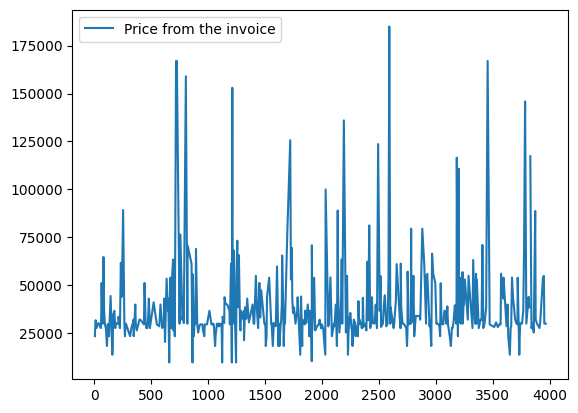

In [15]:
mech_df[mech_df['Item name'] == ('traktor sa kabinom')].plot();

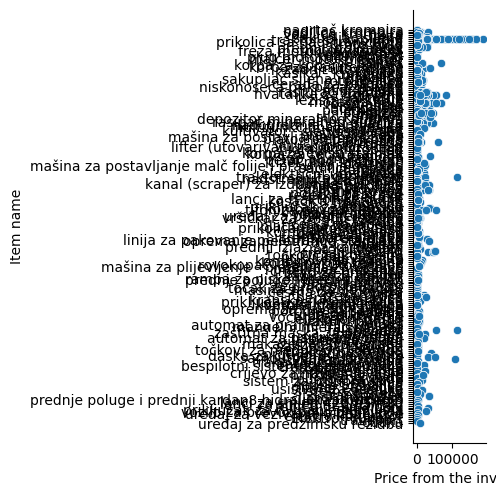

In [16]:
target_col = 'Item name'
num_cols = mech_df.select_dtypes(include='number')
sns.pairplot(mech_df, x_vars=num_cols, y_vars=target_col, height=5, aspect=1, kind='scatter')